## US15

# Objective

The objective of this analysis is to evaluate the annual profitability evolution of a selected railway station using historical financial data. The goal is to apply key descriptive statistics concepts to summarize, describe, and understand patterns in the station’s financial performance over time. Specifically, the analysis will compute central tendency measures, assess dispersion and identify outliers.

# Theoretical Concepts

To analyse the data, the following measures were computed:

## 1. Measures of Central Tendency

- **Mean**: The arithmetic average of the annual profits, calculated as:
  $$
  \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
  $$

- **Median**: The middle value when the profits are sorted. The median is a robust measure of central tendency that is less affected by outliers compared to the mean.
$$
\tilde{x} =
\begin{cases}
\dfrac{x\left( \frac{n}{2} \right) + x\left( \frac{n}{2} + 1 \right)}{2}, & \text{if } n \text{ is even} \\
x\left( \frac{n+1}{2} \right), & \text{if } n \text{ is odd}
\end{cases}
$$


- **Mode**: The most frequent annual profit value. If no value repeats, the mode is considered "None."

## 2. Measures of Variability

- **Standard Deviation (Sample)**: Measures the dispersion of the profits around the mean. It is calculated as:
  $$
  s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (x_i - \bar{x})^2}
  $$

- **Quartiles**: The data is divided into four equal parts:
  - \(Q_1\): 25th percentile (lower quartile),
  - \(Q_2\): 50th percentile (median),
  - \(Q_3\): 75th percentile (upper quartile).



- **Interquartile Range (r_q)**: The range between the first and third quartiles, calculated as:
  $$
  r_q = Q_3 - Q_1.
  $$

- **Outliers**: These are profit values that lie outside the interval:
  $$
  [Q_1 - 1.5 \cdot r_q , \quad Q_3 + 1.5 \cdot r_q].
  $$


In [9]:
import pandas as pd
import statistics as st
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

for col in df.columns[3:]:
    df[col] = [float(i.replace(",", ".")) for i in df[col].astype(str)]

df["Year"] = df["Year"].astype(int)
df["Profit"] = df["Revenues"] - df["Expenses"]

station = input("Enter the station name: ")
while station not in df["Station"].values:
    print("Error: Station not found. Please enter a valid station name.")
    station = input("Enter the station name: ")

df_s = df[df["Station"] == station]

annual_profit = df_s.groupby("Year")["Profit"].sum()
profits = annual_profit.tolist()

mean_val = st.mean(profits)
median_val = st.median(profits)
std_val = st.stdev(profits)
mode_val = st.mode(profits) if profits.count(st.mode(profits)) > 1 else None

quartiles = st.quantiles(profits, n=4)
Q1, Q2, Q3 = quartiles[0], quartiles[1], quartiles[2]
r_q = Q3 - Q1
lower = Q1 - 1.5 * r_q
upper = Q3 + 1.5 * r_q
outliers = [x for x in profits if x < lower or x > upper]

max_profit = max(profits)
min_profit = min(profits)
best_year = annual_profit.idxmax()
worst_year = annual_profit.idxmin()

print(f"\nStatistical Analysis for station: {station}\n")

print("+----------------------+------------+")
print("|      Measure         | Value (M€) |")
print("+----------------------+------------+")
print(f"| {'Mean':<20} | {mean_val:>10.3f} |")
print(f"| {'Standard Deviation':<20} | {std_val:>10.3f} |")
print(f"| {'Median':<20} | {median_val:>10.3f} |")
print(f"| {'Mode':<20} | {mode_val if mode_val is not None else '   None':>10} |")
print("+----------------------+------------+")

print(f"Most profitable year: {best_year} → {max_profit:.3f} M€")
print(f"Least profitable year: {worst_year} → {min_profit:.3f} M€")
print(f"Outliers (M€): {outliers}")


Statistical Analysis for station: Berlin

+----------------------+------------+
|      Measure         | Value (M€) |
+----------------------+------------+
| Mean                 |  11566.759 |
| Standard Deviation   |  12486.256 |
| Median               |   7564.430 |
| Mode                 |       None |
+----------------------+------------+
Most profitable year: 2023 → 39684.900 M€
Least profitable year: 2015 → 655.760 M€
Outliers (M€): [39684.899999999994]


## Statistical Analysis for Station: Berlin

The station **Berlin** was chosen to analyze the annual profitability evolution.

- Most profitable year: 2023, with approximately 39685 million euros.
- Least profitable year: 2015, with about 656 million euros.
- There is a **extreme outlier** in 2023.
- The average annual profit for Berlin Station was 11566.76 M€.


### Analysis of Descriptive Statistics

- The **mean** (11566.76 M€) is higher than the **median** (7564.43 M€), confirming the skewness caused by the outlier.
- The **standard deviation** (12486.26 M€) indicates considerable variability.
- No **mode** was found, showing diversity in yearly profits.
- The median is a more reliable measure of central tendency given the presence of the outlier.

This analysis provides insight into the station’s financial behavior, helping to identify exceptional years (maybe influenced by scenarios' restrictions). In the scope of the Integrative Project, this analysis contributes to find the stations that generate more value and update them.



## US16

## Objective

The objective of this analysis is to perform a comparative evaluation of passenger arrivals across all stations using historical data. The purpose is to understand how passenger traffic is distributed per station, identify patterns and anomalies, and provide visual summaries through boxplots. This will help detect differences in usage and variability between stations, supporting more informed decisions in the simulation.

## Theoretical Concepts

### Descriptive Statistics

To analyse and compare the distributions of passenger arrivals, the following measures and graphical tools were applied:

### 1. Boxplot Construction

Boxplots provide a visual summary of the distribution of a dataset using the following key statistics:

- **Minimum**: The lowest observed value (excluding outliers)
- **First Quartile (Q₁)**: The 25th percentile — 25% of values fall below this point
- **Median (Q₂)**: The 50th percentile — the central value in the ordered dataset
- **Third Quartile (Q₃)**: The 75th percentile — 75% of values fall below this point
- **Maximum**: The highest observed value (excluding outliers)

### 2. Interquartile Range and Outliers

- **Interquartile Range (r_q)**: Describes the middle 50% of the data (range between the first and third quartiles) and is calculated as:

  $$
  r_q = Q_3 - Q_1
  $$

- **Outliers**: Values that fall outside the interval

  $$
  [Q_1 - 1.5 \cdot r_q ,\quad Q_3 + 1.5 \cdot r_q]
  $$

  are considered atypical and are plotted individually in the boxplot.

## Graphical Representation

A boxplot was generated for each station. This type of plot helps to:

- Understand the spread of passenger traffic per station
- Identify stations with higher variability
- Detect possible outliers or unusual traffic spikes
- Visually compare central tendencies and dispersion across multiple stations

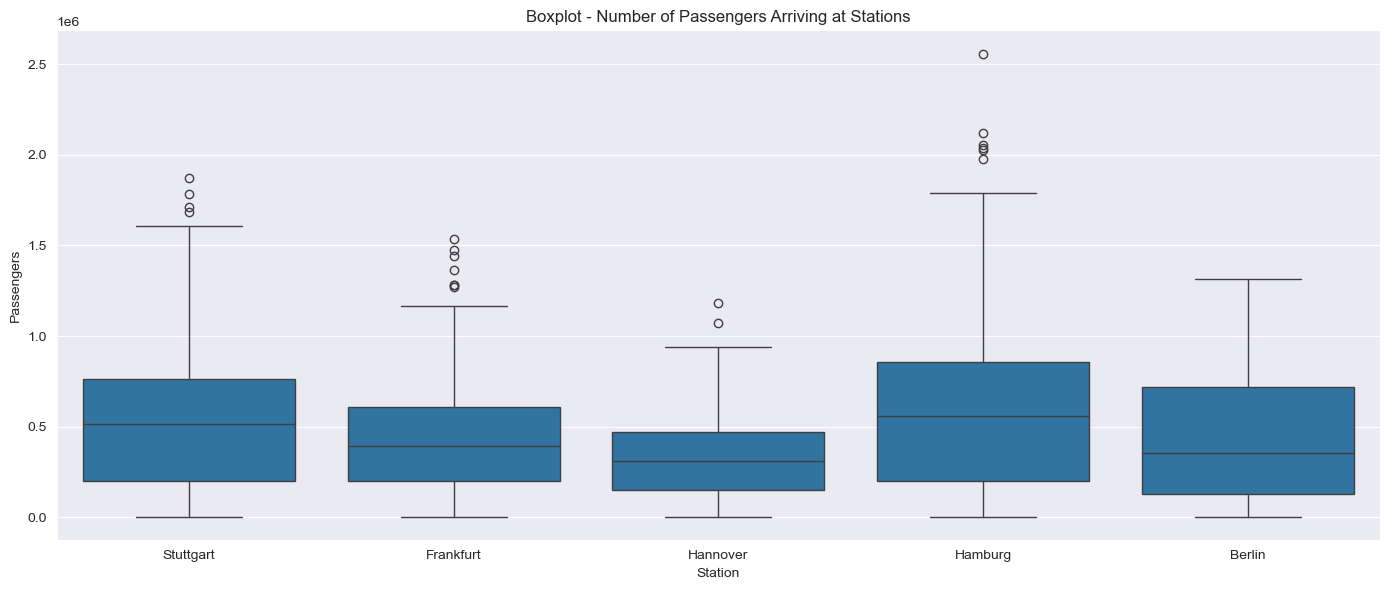

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Stations_Data.csv", sep=';')
df['Passengers'] = df['Passengers'].astype(str).str.replace(',', '.').astype(float)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='Station', y='Passengers')

plt.title("Boxplot - Number of Passengers Arriving at Stations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Analysis and Interpretation of Results

The boxplots provide a statistical comparison of passenger arrivals at each station, based on measures like median, interquartile range (IQR), and outliers.

- Hamburg and Stuttgart show higher medians and greater variability, suggesting they handle large and fluctuating passenger volumes.
- Hannover Station has the lowest median and smallest spread, indicating a more stable and predictable flow.
- Outliers appear in several stations — notably in Hamburg, which displays many extreme values. However, not all stations show outliers (for example, Berlin appears to have none).

### Project Relevance

This statistical insight helps identify strategic stations such as Hamburg and Stuttgart for infrastructure placement (cafés, hotels, etc.), aiming to maximize revenue based on high and variable passenger demand.


## US17

## Objective

The objective of this analysis is to study the distribution of a specific type of cargo arriving at a selected station using historical simulation data. This analysis aims to detect patterns, variability, and potential anomalies by visualising the data through a histogram.

## Theoretical Concepts

### Histogram Construction

A histogram is a graphical representation of data in which:

- **Classes** are displayed on the horizontal axis;
- **Frequencies** are displayed on the vertical axis;
- **Bars** are adjacent and have an area proportional to the frequency of the corresponding class.

In building a histogram for a continuous quantitative variable, each class is an interval of the form \[a, b[ or ]a, b], representing a range of possible values. The following elements must be defined:

- **Class amplitude** (width of each class):

  $$
  \text{Amplitude} = b - a
  $$

- **Class midpoint** (also called mark or characteristic value):

  $$
  \text{Midpoint} = \frac{a + b}{2}
  $$

- **Number of classes (c)** can be estimated using **Sturges' Rule**:

$$
c = Int\left\lfloor 1 + 3.3 \log_{10}(n) \right\rfloor
$$

where \( n \) is the number of observations and $ Int\left\lfloor x \right\rfloor $ denotes the integer part of \( x \).

### Interpretation

Histograms are useful for:

- Understanding the shape and spread of the data;
- Identifying central tendencies, skewness, and variability;
- Detecting outliers or irregular patterns.

Available Stations:
1. Stuttgart
2. Frankfurt
3. Hannover
4. Hamburg
5. Berlin

Available Cargo Types:
1. Iron
2. Coal
3. Prata
4. Vegetables
5. Cereals
6. Wool
7. Coffee
8. Cattle
9. Passengers
10. Mail


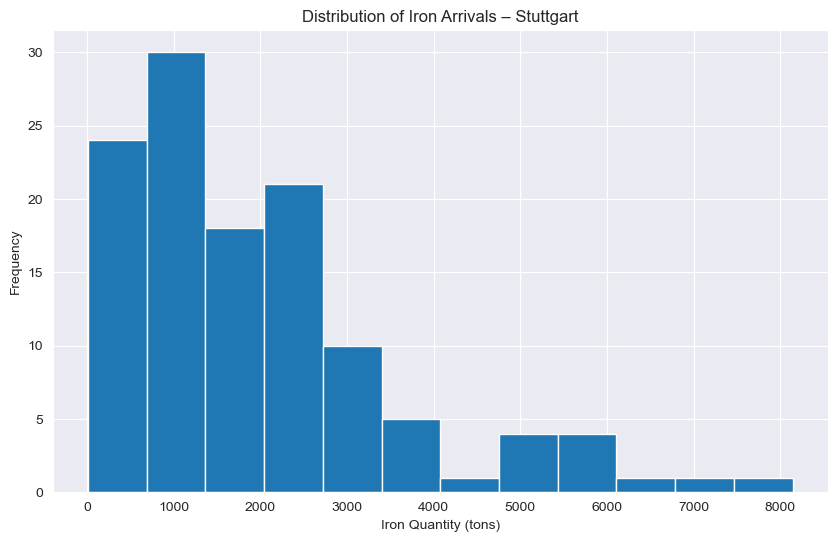

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

cargo_columns = [col for col in df.columns if col not in ['Station', 'Year', 'Month', 'Arrivals', 'Revenues', 'Expenses']]

for col in cargo_columns:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

stations = df['Station'].unique()

print("Available Stations:")
for i, station in enumerate(stations, 1):
    print(f"{i}. {station}")

station_choice = int(input("Choose a station by number: ")) - 1
station_name = stations[station_choice]

print("\nAvailable Cargo Types:")
for i, cargo in enumerate(cargo_columns, 1):
    print(f"{i}. {cargo}")

cargo_choice = int(input("Choose a cargo type by number: ")) - 1
cargo_type = cargo_columns[cargo_choice]

filtered_data = df[df['Station'] == station_name][['Year', 'Month', 'Arrivals', cargo_type]]

plt.figure(figsize=(10, 6))

if cargo_type == "Passengers":
    plt.xlabel(f"Number of {cargo_type}")
else:
    plt.xlabel(f"{cargo_type} Quantity (tons)")

plt.hist(filtered_data[cargo_type], bins='auto')
plt.title(f'Distribution of {cargo_type} Arrivals – {station_name}')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## Statistical Analysis for Station Stuttgart and Cargo Iron

The station **Stuttgart** was chosen to analyze the distribution of **Iron** arrivals using historical simulation data.

- Most frequent arrival quantity: between **500 and 1500 tons**.
- Least frequent arrivals: above **6000 tons**, suggesting possible outliers.
- The histogram shows a **positively skewed distribution**, with a concentration of lower quantity deliveries.
- There is a **long tail** to the right, indicating occasional large iron shipments.

### Analysis of Descriptive Statistics

- The **mode** is around 1000 tons (most common range).
- The **median** is estimated between **1500 and 2500 tons**, showing typical shipment size.
- The **mean** is likely higher than the median, due to the right-skewed shape.
- The **standard deviation** is high, reflecting significant variability.
- The median is a more reliable measure of central tendency due to the influence of high-value outliers.


### Integration with the PI Context

In the context of the **Projeto Integrador (PI)**, this graphical representation allows the player to better understand how cargo traffic varies by station and cargo type. The histograms help identify which cargo types are being transported more frequently in specific stations.

The presence of exceptionally high iron arrivals may indicate a scenario period related to **wartime conditions**, where iron demand and transportation are intensified.

## US18

## Objective

The objective of this analysis is to study the distribution of train arrivals, passengers, and mail across different stations using historical simulation data. This analysis aims to provide insights into how these elements are allocated among the stations, detect patterns, and identify any anomalies in the distribution.

## Theoretical Concepts

### Circular Chart (Pie Chart) Construction

A circular chart (pie chart) is a graphical representation of data in which the data is displayed as sectors or slices of a circle, where the area (and corresponding angle) of each sector is proportional to the frequency of the category it represents. The frequency of each category is calculated as:

- **Absolute Frequency**: The number of observations corresponding to category \(i\), denoted as \(n_i\).

  $$ \sum_{i=1}^{c} n_i = n $$

  where \(n\) is the total number of observations, and \(c\) is the number of categories.

- **Relative Frequency**: The ratio of the absolute frequency of category \(i\) to the total number of observations. The formula is:

  $$ f_i = \frac{n_i}{n} $$

  where \( f_i \) represents the relative frequency of category \(i\), and \(n_i\) is the absolute frequency of category \(i\).

In this analysis, each pie chart represents the distribution of train arrivals, passengers, and mail across different stations. The size of each segment in the chart corresponds to the relative frequency of each station in each category.

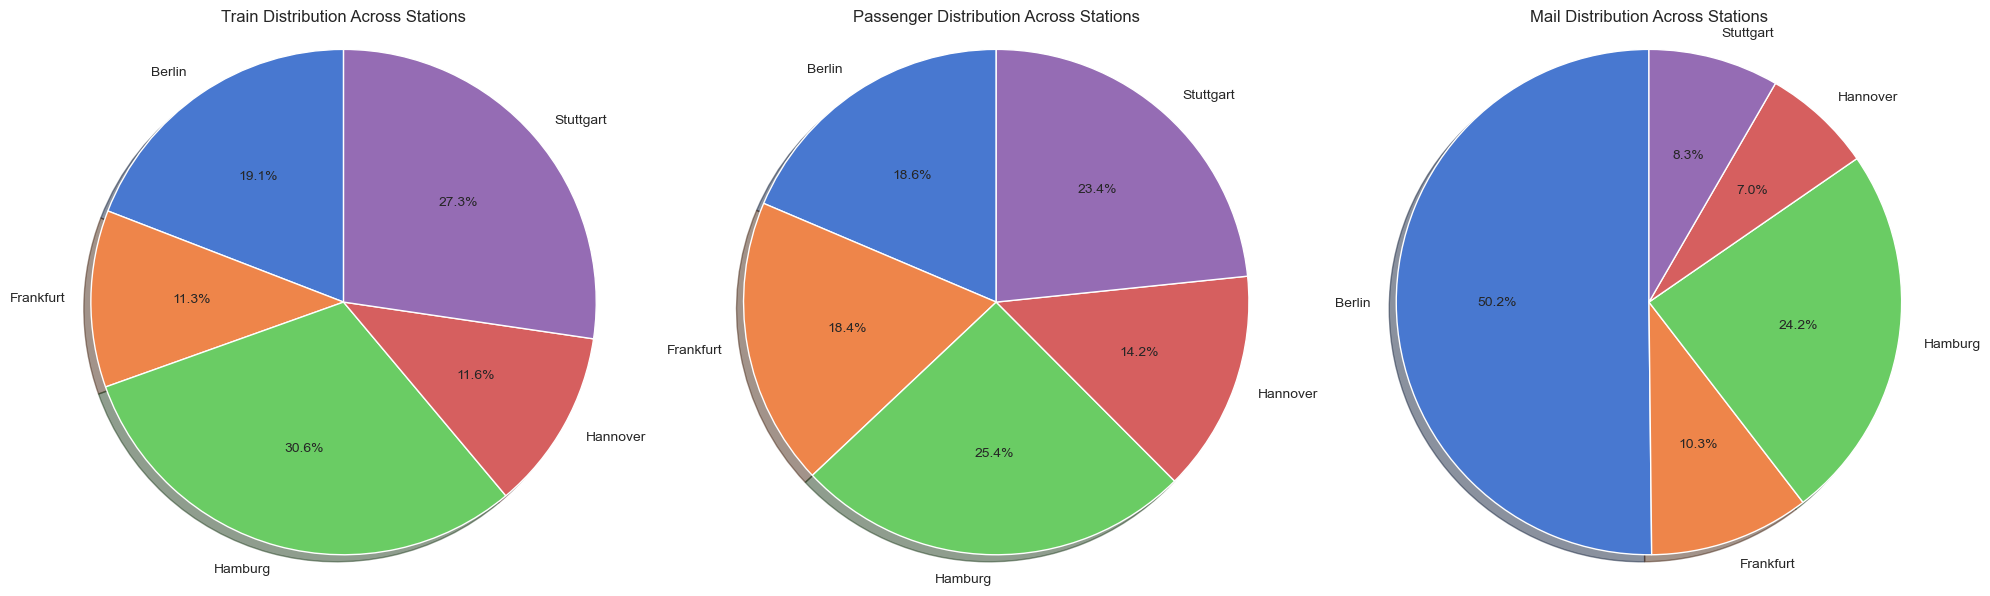

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

columns_to_convert = ['Arrivals', 'Passengers', 'Mail']

for col in columns_to_convert:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = df[col].astype(float)

station_data = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum()

def plot_pie_charts_aligned(data):
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))  # 1 linha, 3 colunas

    columns = ['Arrivals', 'Passengers', 'Mail']
    titles = ['Train Distribution Across Stations',
              'Passenger Distribution Across Stations',
              'Mail Distribution Across Stations']

    for ax, column, title in zip(axes, columns, titles):
        ax.pie(
            data[column],
            labels=data.index,
            autopct='%1.1f%%',
            shadow=True,
            startangle=90,
            colors=sns.color_palette('muted')
        )
        ax.set_title(title)
        ax.axis('equal')

    plt.tight_layout()
    plt.show()

plot_pie_charts_aligned(station_data)


### Analysis and Interpretation of Results

The pie charts reveal the following distributions:

- **Train Arrivals**: The station **Hamburg** concentrates the highest share of train traffic (30.6%), followed by **Stuttgart** (27.3%) and **Berlin** (19.1%). This suggests that Hamburg and Stuttgart are key stations.

- **Passengers**: The passenger distribution is led by **Hamburg** (25.4%) and **Stuttgart** (23.4%). **Hannover** appears with the smallest share (14.2%), suggesting less demand or a more regional role. However, there isn't a big difference in distribution.

- **Mail**:The station **Berlin** stands out with the highest share of mail traffic (50.2%), followed by **Hamburg** (24.2%). The remaining stations—**Frankfurt** (10.3%), **Stuttgart** (8.3%), and **Hannover** (7.0%)—handle considerably less, reinforcing Berlin's central role in postal logistics.

### Integration with the PI Context

In the context of the **Projeto Integrador (PI)**, these visualizations assist players in:

- Identifying which stations handle the highest volumes in each category;
- Prioritizing upgrade stations with higher volume  (upgrades can be hotels, cafés,..);
- Increase the number of routes in the stations with the highest volume.